# NYC Taxi Times

**Author:** Clarice Mottet  

---

## Objective

Build a model to predict the total ride duration for NYC taxis

---

## Dataset
**Source:**
- kaggle


## Table of Contents

- [1. Load Data](#1-load-data)
- [2. Data Overview](#2-data-overview)
- [3. Data Cleaning](#3-data-cleaning)
- [4. Feature Engineering](#4-feature-enginerring)
- [5. Exploratory Data Analysis](#5-exploratory-data-analysis)
- [6. Correlation Analysis](#6-correlation-analysis)
- [7. Modeling](#7-modeling)
- [8. Conclusion](#8-conclusion)


## Notes

- Random seed = 42
- Train/Test split = pre-determined by datasets given
- Evaluation metric = Root Mean Squared Log Error

# 1. Load Data

In [171]:
#libraries

import pandas as pd
import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt

project_root = Path.cwd().parent          # if notebook is inside notebooks/


* Import in train and test datasets

In [172]:
#import in the datasets

#establish filepath
raw_path = project_root / "data" / "raw"
os.listdir(raw_path)

df_test = pd.read_csv(raw_path / "test.csv", dtype = str)
df_train = pd.read_csv(raw_path / "train.csv", dtype = str)
df_sample = pd.read_csv(raw_path / "sample_submission.csv", dtype = str)

# 2. Data Overview

- number of rows
- number of columns
- same columns in both datasets

In [173]:
#number of rows
print(f"df_train rows: {len(df_train)}")
print(f"df_test rows: {len(df_test)}")

list_test_col = list(df_test.columns)
list_train_col = list(df_train.columns)

list_all_col = list_test_col + list_train_col
list_all_col = list(set(list_all_col))
print(f"all columns: {list_all_col}")

list_test_doesnt = [x for x in list_all_col if x not in list_test_col]
print(f"columns not included in test: {list_test_doesnt}")

list_train_doesnt = [x for x in list_all_col if x not in list_train_col]
print(f"columns not included in train: {list_train_doesnt}")


df_train rows: 1458644
df_test rows: 625134
all columns: ['pickup_latitude', 'pickup_longitude', 'pickup_datetime', 'dropoff_datetime', 'trip_duration', 'id', 'passenger_count', 'vendor_id', 'dropoff_latitude', 'store_and_fwd_flag', 'dropoff_longitude']
columns not included in test: ['dropoff_datetime', 'trip_duration']
columns not included in train: []


# 3. Data Cleaning

* dtype
* nulls
* duplicates

In [174]:
#dtype

for col in df_train.columns:
    df_train[col] = df_train[col].str.strip()

#numeric columns
list_col_num = ['vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
                'trip_duration']
list_col_date = ['pickup_datetime', 'dropoff_datetime']

#convert to numberic

list_convert_num = [x for x in list_col_num if x in df_train.columns]
df_train[list_convert_num] = df_train[list_convert_num].apply(pd.to_numeric)

list_convert_num = [x for x in list_col_num if x in df_test.columns]
df_test[list_convert_num] = df_test[list_convert_num].apply(pd.to_numeric)

#convert to datetime

list_convert_date = [x for x in list_col_date if x in df_train.columns]
df_train[list_convert_date] = df_train[list_convert_date].apply(pd.to_datetime)

list_convert_date = [x for x in list_col_date if x in df_test.columns]
df_test[list_convert_date] = df_test[list_convert_date].apply(pd.to_datetime)


In [175]:
#nulls

print("null counts:")
print(df_train.isnull().sum())

print("\nunique value counts:")
print(df_train.nunique())

null counts:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

unique value counts:
id                    1458644
vendor_id                   2
pickup_datetime       1380222
dropoff_datetime      1380377
passenger_count            10
pickup_longitude        23047
pickup_latitude         45245
dropoff_longitude       33821
dropoff_latitude        62519
store_and_fwd_flag          2
trip_duration            7417
dtype: int64


In [176]:
#duplicates

#duplicates by id
dup_id_count = df_train.duplicated(subset='id').sum()
print(f"duplicate rows by 'id': {dup_id_count}")

#duplicates by all columns except id
cols_no_id = [col for col in df_train.columns if col != 'id']
dup_no_id_count = df_train.duplicated(subset=cols_no_id).sum()
print(f"duplicate rows by all columns except 'id': {dup_no_id_count}")


duplicate rows by 'id': 0
duplicate rows by all columns except 'id': 7


In [177]:
#explored data in another notebook and found the below needs to be cleaned

def clean_data(df_):
    """
    - removes instances where passenger count is 60
    - removes instances where trip duration is less than 10 seconds or more than 3 hours
    - remove instances where the pickup and dropoff location is the same but the trip_duration is more than 15 minutes
    - remove instances where the longitude and latitude are outside of NYC and the suburb area
    """

    #removes instances where passenger count is 0
    mask_passenger_count = (df_['passenger_count']>0)

    #removes instances where the trip duration is less than a min, more than 4 hours
    MIN_DURATION = 10
    # MIN_DURATION = 60
    # MAX_DURATION = 14400
    MAX_DURATION = 10800
    mask_duration = (df_['trip_duration'].between(MIN_DURATION, MAX_DURATION))

    #removes instances where pickup/dropoff is the same and the trip is more than 15 min
    # mask_same_loc = (
    #         (df_['pickup_longitude']==df_['dropoff_longitude']) &
    #         (df_['pickup_latitude']==df_['dropoff_latitude']) &
    #         (df_['trip_duration']>900)
    #         )

    #removes instances where the trip is outside NYC
    MIN_LONGITUDE = -74.30
    MAX_LONGITUDE = -73.60

    MIN_LATITUDE = 40.45
    MAX_LATITUDE = 41.00

    mask_range = (
        df_['pickup_longitude'].between(MIN_LONGITUDE, MAX_LONGITUDE) &
        df_['dropoff_longitude'].between(MIN_LONGITUDE, MAX_LONGITUDE) &
        df_['pickup_latitude'].between(MIN_LATITUDE, MAX_LATITUDE) &
        df_['dropoff_latitude'].between(MIN_LATITUDE, MAX_LATITUDE)
        )

    df_ = df_[mask_passenger_count & mask_duration & mask_range].copy()
    # df_ = df_[~mask_same_loc].copy()
    df_.reset_index(drop = True, inplace = True)

    return df_


In [178]:
before_len = len(df_train)
print(f"records before cleaning: {len(df_train)}")
df_train = clean_data(df_train)
after_len = len(df_train)
print(f"records after cleaning: {len(df_train)}")
record_rmv = before_len - after_len
print(f"records removed: {record_rmv}")

records before cleaning: 1458644
records after cleaning: 1453915
records removed: 4729


# 4. Feature Engineering

- haversine distance + log
- manhattan distance + log
- cyclical hour, weekday, month variables
- is weekend: indicator 0 if weekday, 1 if weekend
- bearing: direction where the trip was going from pickup to dropoff


In [179]:
#haversine and manhattan distance

df_train["log_trip_duration"] = np.log1p(df_train["trip_duration"])

# Earth's radius in kilometers
R = 6371

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the Haversine distance between two points (in km).
    """
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


In [180]:
# Haversine distance
df_train["haversine_distance"] = haversine_distance(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["dropoff_longitude"]
)

# Manhattan distance (north-south + east-west)
lat_distance = haversine_distance(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["pickup_longitude"]
)

lon_distance = haversine_distance(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["pickup_latitude"],
    df_train["dropoff_longitude"]
)

df_train["manhattan_distance"] = lat_distance + lon_distance

df_train['log_haversine_distance'] = np.log1p(df_train["haversine_distance"])
df_train['log_manhattan_distance'] = np.log1p(df_train["manhattan_distance"])

df_train[["haversine_distance", "manhattan_distance"]].describe()

,haversine_distance,manhattan_distance
count,1.453915e+06,1.453915e+06
mean,3.429635e+00,4.432873e+00
std,3.890125e+00,5.174886e+00
min,0.000000e+00,0.000000e+00
25%,1.234703e+00,1.574737e+00
50%,2.095972e+00,2.691534e+00
75%,3.876081e+00,4.999987e+00
max,4.776513e+01,6.761568e+01


In [181]:
# Haversine distance
df_test["haversine_distance"] = haversine_distance(
    df_test["pickup_latitude"],
    df_test["pickup_longitude"],
    df_test["dropoff_latitude"],
    df_test["dropoff_longitude"]
)

# Manhattan distance (north-south + east-west)
lat_distance = haversine_distance(
    df_test["pickup_latitude"],
    df_test["pickup_longitude"],
    df_test["dropoff_latitude"],
    df_test["pickup_longitude"]
)

lon_distance = haversine_distance(
    df_test["pickup_latitude"],
    df_test["pickup_longitude"],
    df_test["pickup_latitude"],
    df_test["dropoff_longitude"]
)

df_test["manhattan_distance"] = lat_distance + lon_distance

df_test['log_haversine_distance'] = np.log1p(df_test["haversine_distance"])
df_test['log_manhattan_distance'] = np.log1p(df_test["manhattan_distance"])

In [182]:
#create hour, weekday and month cyclical variables

def convert_hour(df_, col_):
    df_["hour_"+col_] = df_[col_].dt.hour
    df_["hour_sin_"+col_] = np.sin(2 * np.pi * df_["hour_"+col_] / 24)
    df_["hour_cos_"+col_] = np.cos(2 * np.pi * df_["hour_"+col_] / 24)
    return df_

def convert_day_of_week(df_, col_):
    df_["dow_"+col_] = df_[col_].dt.dayofweek
    df_["dow_sin_"+col_] = np.sin(2*np.pi*df_["dow_"+col_]/7)
    df_["dow_cos_"+col_] = np.cos(2*np.pi*df_["dow_"+col_]/7)
    return df_

def convert_month(df_, col_):
    df_["month_"+col_] = df_[col_].dt.month
    df_["month_sin_"+col_] = np.sin(2*np.pi*df_["month_"+col_]/12)
    df_["month_cos_"+col_] = np.cos(2*np.pi*df_["month_"+col_]/12)
    return df_


In [183]:
df_train = convert_hour(df_train, "pickup_datetime")
df_train = convert_day_of_week(df_train, "pickup_datetime")
df_train = convert_month(df_train, "pickup_datetime")

df_test = convert_hour(df_test, "pickup_datetime")
df_test = convert_day_of_week(df_test, "pickup_datetime")
df_test = convert_month(df_test, "pickup_datetime")

In [184]:
#is weekend

df_train["is_weekend"] = df_train["dow_pickup_datetime"].isin([5, 6]).astype(int)
df_test["is_weekend"] = df_test["dow_pickup_datetime"].isin([5, 6]).astype(int)

In [185]:
#bearing 


def calculate_bearing(lat1, lon1, lat2, lon2):
    """
    Calculate the initial compass bearing (in degrees, 0-360) from point 1 to point 2.
    """
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlon = lon2 - lon1

    x = np.sin(dlon) * np.cos(lat2)
    y = (
        np.cos(lat1) * np.sin(lat2)
        - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    )

    bearing = np.degrees(np.arctan2(x, y))

    return (bearing + 360) % 360

df_train["bearing"] = calculate_bearing(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["dropoff_longitude"]
)

df_test["bearing"] = calculate_bearing(
    df_test["pickup_latitude"],
    df_test["pickup_longitude"],
    df_test["dropoff_latitude"],
    df_test["dropoff_longitude"]
)

df_train["bearing_sin"] = np.sin(
    2 * np.pi * df_train["bearing"] / 360
)
df_train["bearing_cos"] = np.cos(
    2 * np.pi * df_train["bearing"] / 360
)

df_test["bearing_sin"] = np.sin(
    2 * np.pi * df_test["bearing"] / 360
)
df_test["bearing_cos"] = np.cos(
    2 * np.pi * df_test["bearing"] / 360
)

In [186]:
#one hot encoding

df_train['store_and_fwd_flag_ind'] = 0
df_train.loc[df_train['store_and_fwd_flag']=='Y', 'store_and_fwd_flag_ind'] = 1

df_test['store_and_fwd_flag_ind'] = 0
df_test.loc[df_test['store_and_fwd_flag']=='Y', 'store_and_fwd_flag_ind'] = 1


df_train['vendor_id_1'] = 0
df_train.loc[df_train['vendor_id']==1, 'vendor_id_1'] = 1
df_train['vendor_id_2'] = 0
df_train.loc[df_train['vendor_id']==2, 'vendor_id_2'] = 1

df_test['vendor_id_1'] = 0
df_test.loc[df_test['vendor_id']==1, 'vendor_id_1'] = 1
df_test['vendor_id_2'] = 0
df_test.loc[df_test['vendor_id']==2, 'vendor_id_2'] = 1


# 5. Exploratory Data Analysis

- Review Trip Duration (target will be log trip duration, trip duration is heavily skewed)
- Reviewed hour of day and day of week by trip duration, varies slightly
- distribution of passenger count varies greatly, there is mostly only 1 passenger
- scatter plot of distance and trip duration doesn't reveal anything out of the normal

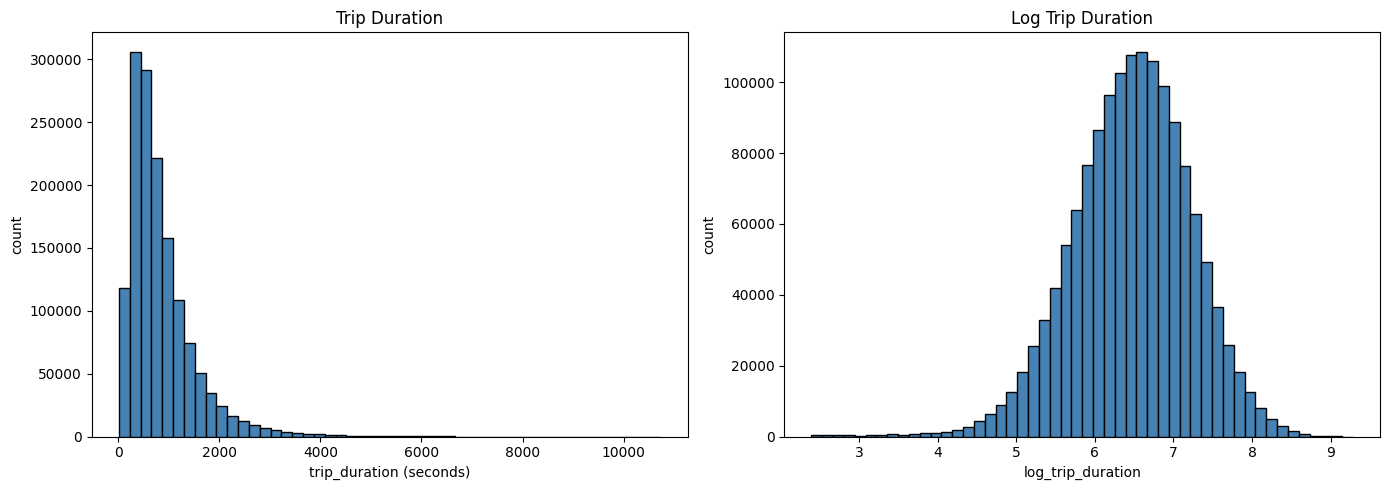

In [187]:
#trip duration histogram

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_train["trip_duration"], bins=50, color="steelblue", edgecolor="black")
axes[0].set_title("Trip Duration")
axes[0].set_xlabel("trip_duration (seconds)")
axes[0].set_ylabel("count")

axes[1].hist(df_train["log_trip_duration"], bins=50, color="steelblue", edgecolor="black")
axes[1].set_title("Log Trip Duration")
axes[1].set_xlabel("log_trip_duration")
axes[1].set_ylabel("count")

plt.tight_layout()
plt.show()

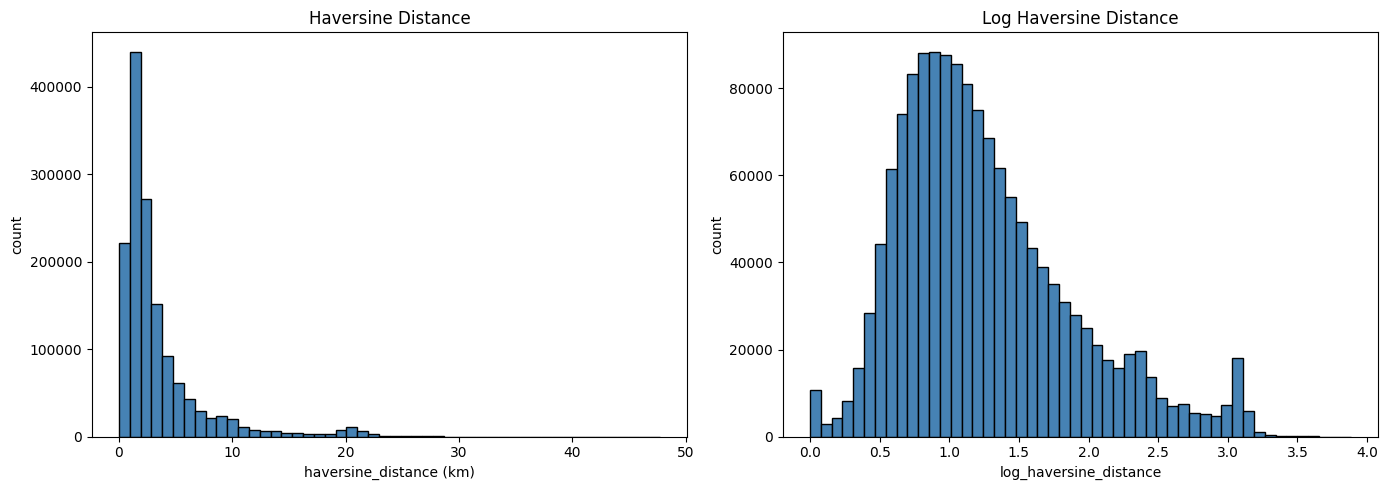

In [188]:
#histogram haversine distance

#haversine distance histogram

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_train["haversine_distance"], bins=50, color="steelblue", edgecolor="black")
axes[0].set_title("Haversine Distance")
axes[0].set_xlabel("haversine_distance (km)")
axes[0].set_ylabel("count")

axes[1].hist(df_train["log_haversine_distance"], bins=50, color="steelblue", edgecolor="black")
axes[1].set_title("Log Haversine Distance")
axes[1].set_xlabel("log_haversine_distance")
axes[1].set_ylabel("count")

plt.tight_layout()
plt.show()


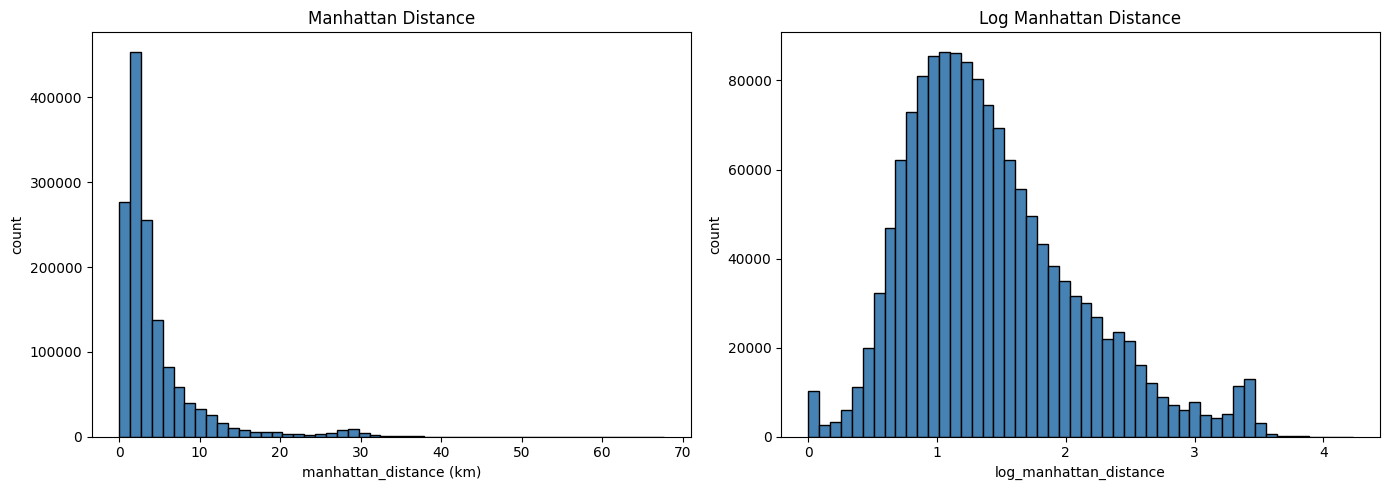

In [189]:
#manhattan distance histogram

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_train["manhattan_distance"], bins=50, color="steelblue", edgecolor="black")
axes[0].set_title("Manhattan Distance")
axes[0].set_xlabel("manhattan_distance (km)")
axes[0].set_ylabel("count")

axes[1].hist(df_train["log_manhattan_distance"], bins=50, color="steelblue", edgecolor="black")
axes[1].set_title("Log Manhattan Distance")
axes[1].set_xlabel("log_manhattan_distance")
axes[1].set_ylabel("count")

plt.tight_layout()
plt.show()


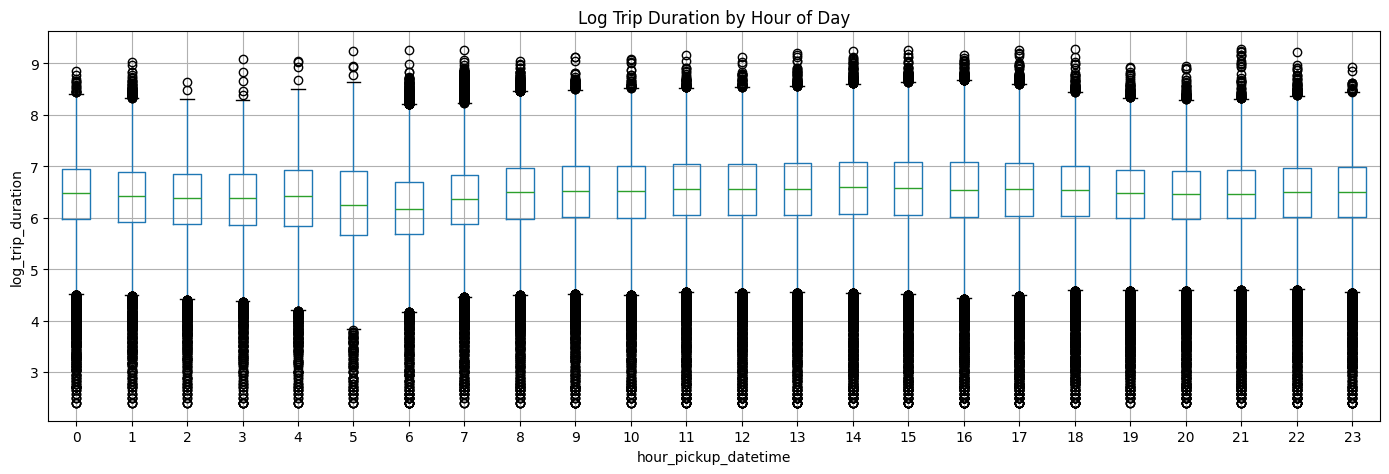

In [190]:
#box plot of log trip duration by hour of day

fig, ax = plt.subplots(figsize=(14, 5))

df_train.boxplot(column="log_trip_duration", by="hour_pickup_datetime", ax=ax)

ax.set_title("Log Trip Duration by Hour of Day")
plt.suptitle("")
ax.set_xlabel("hour_pickup_datetime")
ax.set_ylabel("log_trip_duration")

plt.tight_layout()
plt.show()


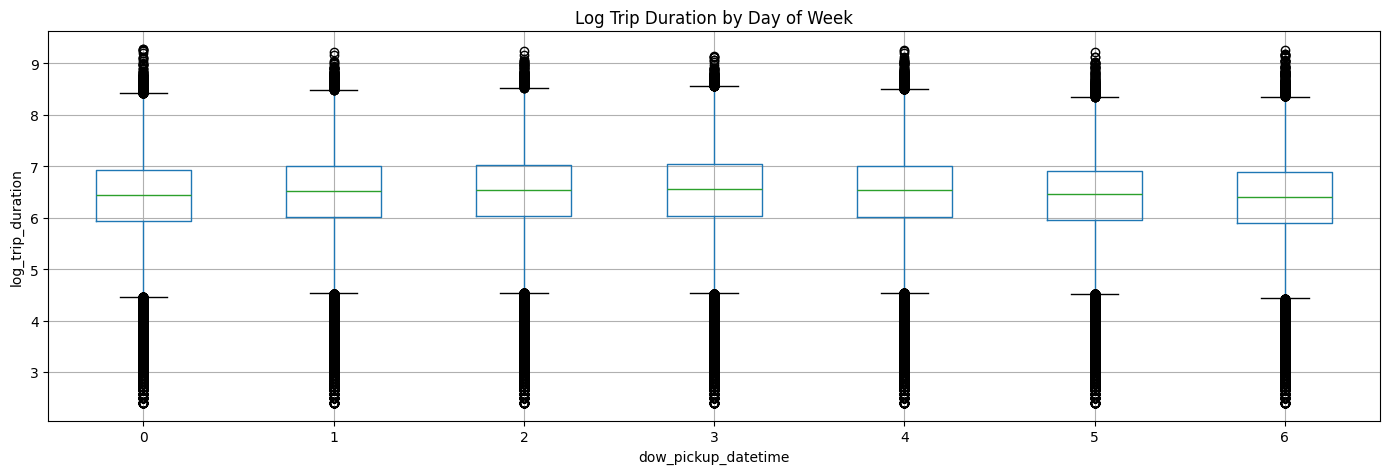

In [191]:
#box plot of log trip duration by day of week

fig, ax = plt.subplots(figsize=(14, 5))

df_train.boxplot(column="log_trip_duration", by="dow_pickup_datetime", ax=ax)

ax.set_title("Log Trip Duration by Day of Week")
plt.suptitle("")
ax.set_xlabel("dow_pickup_datetime")
ax.set_ylabel("log_trip_duration")

plt.tight_layout()
plt.show()


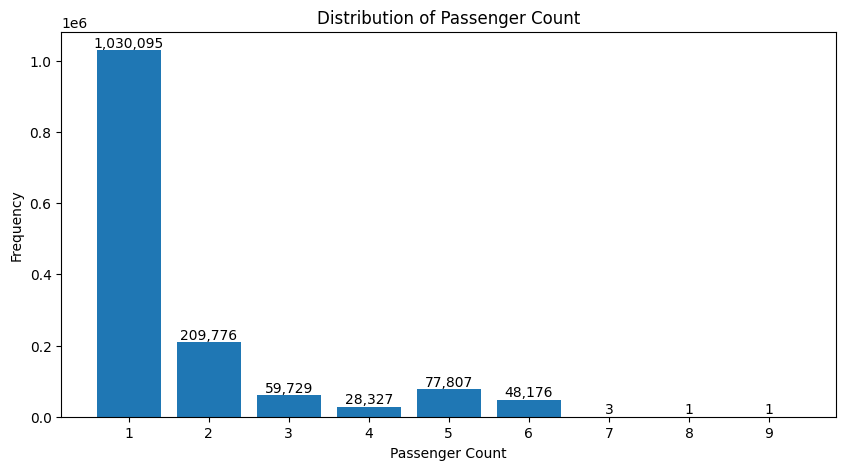

In [192]:
#passenger count

import matplotlib.pyplot as plt

passenger_counts = (
    df_train["passenger_count"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    passenger_counts.index,
    passenger_counts.values
)

# Add frequency labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xlabel("Passenger Count")
plt.ylabel("Frequency")
plt.title("Distribution of Passenger Count")

plt.xticks(passenger_counts.index)

plt.show()

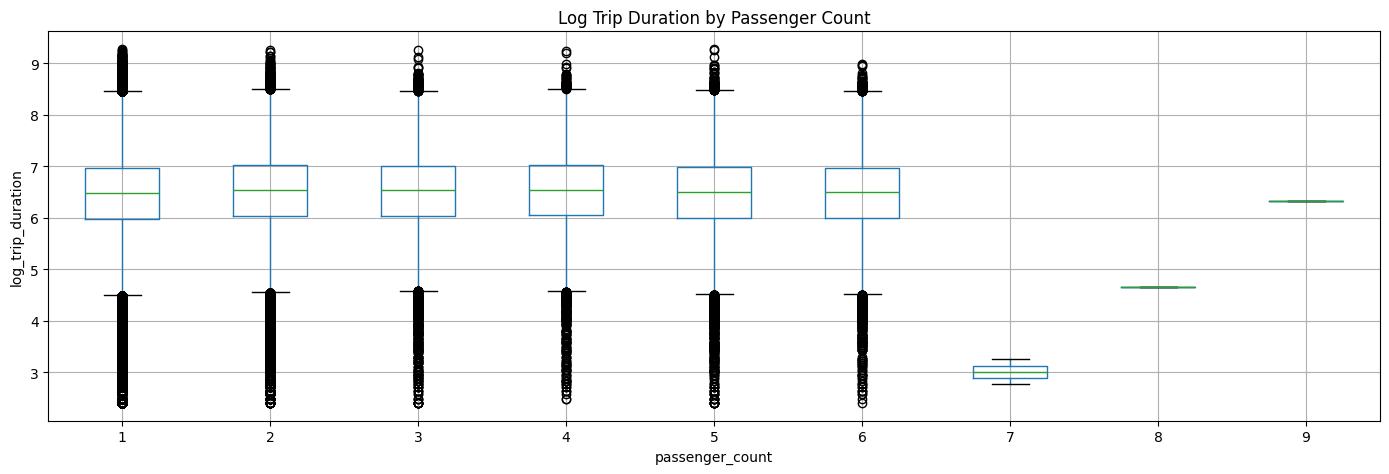

In [193]:
#box plot of log trip duration by passenger count

fig, ax = plt.subplots(figsize=(14, 5))

df_train.boxplot(column="log_trip_duration", by="passenger_count", ax=ax)

ax.set_title("Log Trip Duration by Passenger Count")
plt.suptitle("")
ax.set_xlabel("passenger_count")
ax.set_ylabel("log_trip_duration")

plt.tight_layout()
plt.show()


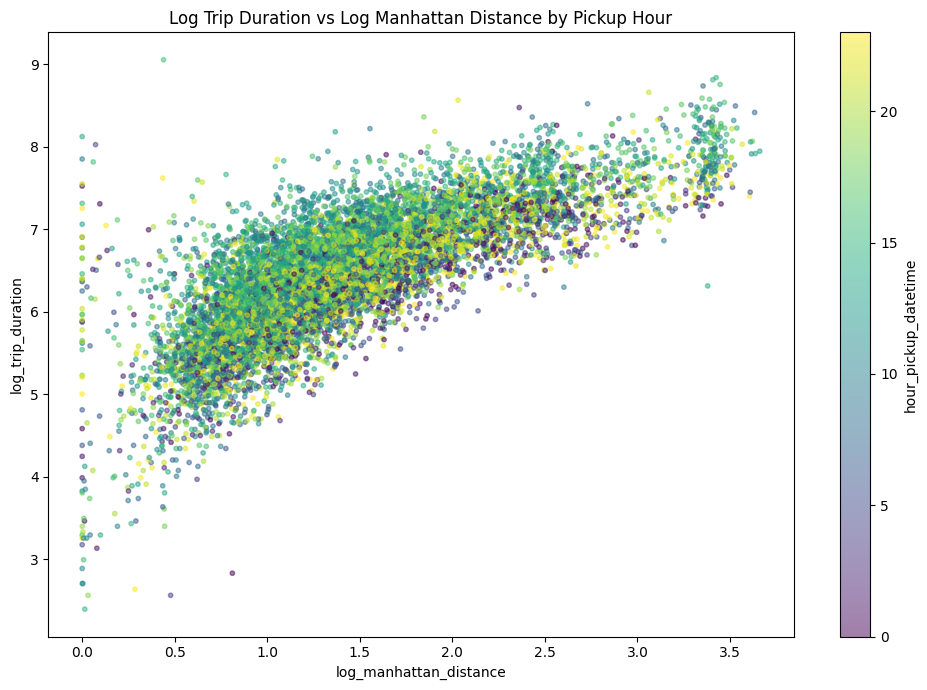

In [194]:
#scatter plot of log trip duration vs log manhattan distance, colored by pickup hour

df_plot_sample = df_train.sample(n=10000, random_state=42)

fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    df_plot_sample["log_manhattan_distance"],
    df_plot_sample["log_trip_duration"],
    c=df_plot_sample["hour_pickup_datetime"],
    cmap="viridis",
    alpha=0.5,
    s=10
)

ax.set_title("Log Trip Duration vs Log Manhattan Distance by Pickup Hour")
ax.set_xlabel("log_manhattan_distance")
ax.set_ylabel("log_trip_duration")

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("hour_pickup_datetime")

plt.tight_layout()
plt.show()


# 6. Correlation Analysis


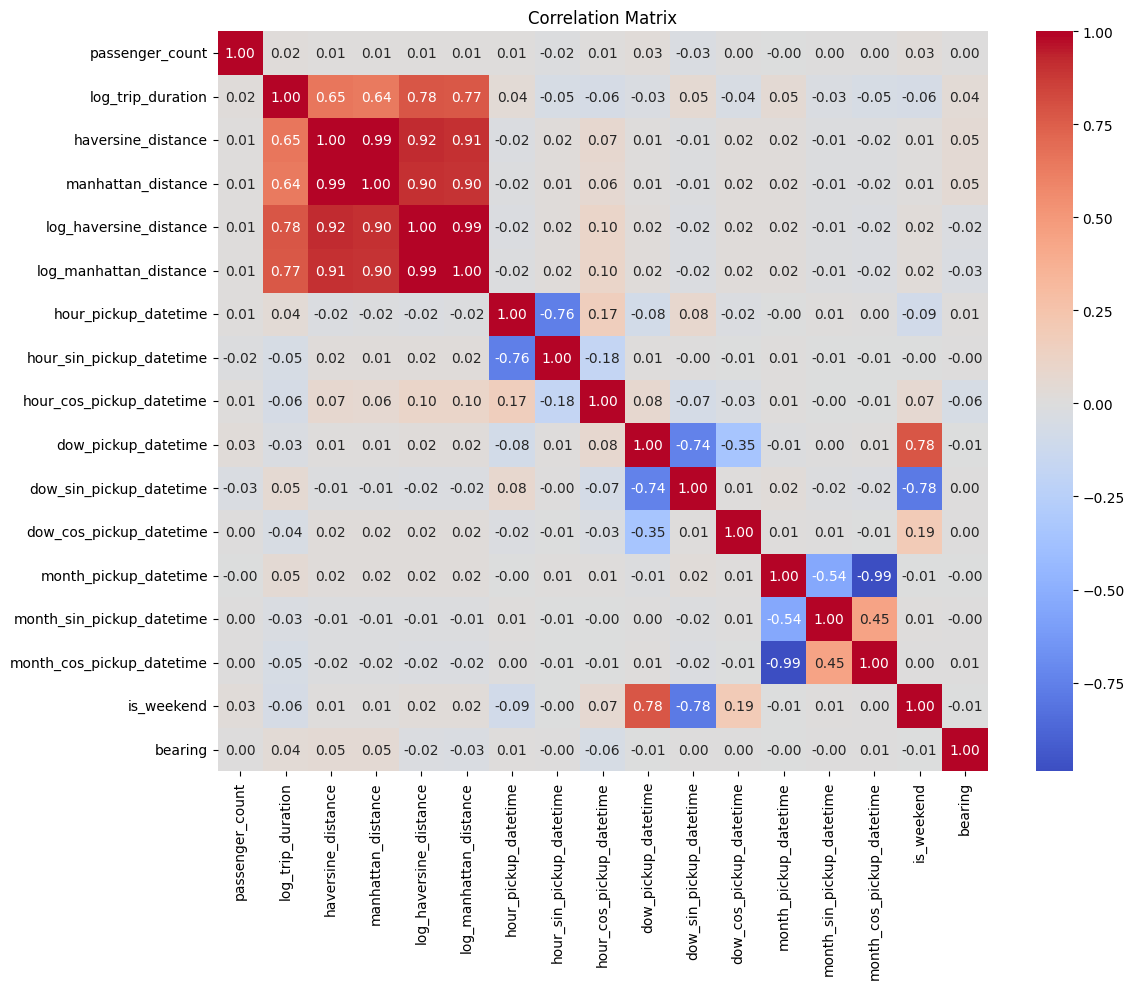

In [195]:
#correlation matrix

list_col_corr = [
    'passenger_count', 'log_trip_duration', 'haversine_distance',
    'manhattan_distance', 'log_haversine_distance',
    'log_manhattan_distance', 'hour_pickup_datetime',
    'hour_sin_pickup_datetime', 'hour_cos_pickup_datetime',
    'dow_pickup_datetime', 'dow_sin_pickup_datetime',
    'dow_cos_pickup_datetime', 'month_pickup_datetime',
    'month_sin_pickup_datetime', 'month_cos_pickup_datetime', 'is_weekend',
    'bearing'
]

corr_matrix = df_train[list_col_corr].corr()

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

ax.set_title("Correlation Matrix")

plt.tight_layout()
plt.show()


In [196]:
df_train.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
       'trip_duration', 'log_trip_duration', 'haversine_distance',
       'manhattan_distance', 'log_haversine_distance',
       'log_manhattan_distance', 'hour_pickup_datetime',
       'hour_sin_pickup_datetime', 'hour_cos_pickup_datetime',
       'dow_pickup_datetime', 'dow_sin_pickup_datetime',
       'dow_cos_pickup_datetime', 'month_pickup_datetime',
       'month_sin_pickup_datetime', 'month_cos_pickup_datetime', 'is_weekend',
       'bearing', 'bearing_sin', 'bearing_cos', 'store_and_fwd_flag_ind',
       'vendor_id_1', 'vendor_id_2'],
      dtype='object')

# 7. Modeling

Baseline
- train/val split, standard scale
- mlflow creation
- evaluation metrics
- check previous runs code added so that if I'm tuning hyper parameters for a model I don't rerun a model with the same hyper parameters

Models
- LASSO

In [ ]:
#train/val split, standard scale

#all features
# features = [
#        'passenger_count',
#        'pickup_longitude', 'pickup_latitude',
#        'dropoff_longitude', 'dropoff_latitude', 
#        'haversine_distance',
#        'manhattan_distance',
#        'log_haversine_distance',
#        'log_manhattan_distance', 
#        'hour_pickup_datetime',
#        'hour_sin_pickup_datetime',
#        'hour_cos_pickup_datetime',
#        'dow_pickup_datetime',
#        'dow_sin_pickup_datetime',
#        'dow_cos_pickup_datetime',
#        'month_pickup_datetime',
#        'month_sin_pickup_datetime',
#        'month_cos_pickup_datetime',
#        'is_weekend',
#        'bearing',
#        'bearing_sin',
#        'bearing_cos',
#        'store_and_fwd_flag_ind',
#        'vendor_id_1',
#        'vendor_id_2']

features = [
       'passenger_count',
       'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 
       'haversine_distance',
    #    'log_haversine_distance',
       'hour_sin_pickup_datetime',
       'hour_cos_pickup_datetime',
       'dow_sin_pickup_datetime',
       'dow_cos_pickup_datetime',
       'month_sin_pickup_datetime',
       'month_cos_pickup_datetime',
       'is_weekend',
       'store_and_fwd_flag_ind',
       'vendor_id_1',
       'vendor_id_2']


#removed distnaces that weren't "log"
#removed
        # 'log_manhattan_distance', 
#removed bearing_sin, bearing_cos and replaced with bearing
    #    'bearing_sin',
    #    'bearing_cos',

#going to remove pickup_datetime and then StandardScale the variables

target = 'log_trip_duration'
# target = 'trip_duration'


X = df_train[features].copy()
y = df_train[target].copy()

X_test = df_test[features].copy()

#scale the features
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [ ]:
#set up mlflow

import mlflow

# Store MLflow runs locally in this project
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Group all taxi-model runs together
mlflow.set_experiment("NYC Taxi Trip Duration")

# #run in terminal
#need to cd to where my file is first

# mlflow ui --backend-store-uri sqlite:///mlflow.db

# #open in browser
# http://127.0.0.1:5000

<Experiment: artifact_location='/Users/claricemottet/Documents/code_projects/kaggle_NYC_taxi_times/kaggle_NYC_taxi_times/exploratory_notebooks/mlruns/1', creation_time=1793486478507, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793486478507, lifecycle_stage='active', name='NYC Taxi Trip Duration', tags={}, trace_location=None, workspace='default'>

In [199]:
#evaluation metrics

from sklearn.metrics import root_mean_squared_log_error, root_mean_squared_error, r2_score


In [200]:
#check for a previous run with the same hyperparameters before retraining

class StopExecution(Exception):
    """Raised to halt cell execution without printing a traceback."""
    def _render_traceback_(self):
        pass

def check_previous_run(params, experiment_name="NYC Taxi Trip Duration"):
    """
    Looks for a previous mlflow run (in experiment_name) whose logged
    params exactly match the given params dict. If found, prints that
    run's evaluation metrics and asks whether to continue anyway.
    Raises StopExecution if the user chooses not to continue.
    """
    client = mlflow.tracking.MlflowClient()
    experiment = client.get_experiment_by_name(experiment_name)

    if experiment is None:
        return

    runs = client.search_runs(experiment_ids=[experiment.experiment_id])

    #mlflow stores all logged params as strings, so compare against str(v)
    params_str = {k: str(v) for k, v in params.items()}

    for run in runs:
        run_params = run.data.params
        same_params = all(run_params.get(k) == v for k, v in params_str.items())

        if same_params:
            print(f"Found a previous run with identical parameters (run_id: {run.info.run_id})")
            print("Parameters:")
            for k, v in params.items():
                print(f"  {k}: {v}")

            print("Evaluation metrics from that run:")
            for metric_name, metric_value in run.data.metrics.items():
                print(f"  {metric_name}: {metric_value:.4f}")

            answer = input("A run with these exact parameters already exists. Continue anyway? (y/n): ")
            if answer.strip().lower() != "y":
                raise StopExecution("Stopped: a run with these exact parameters already exists.")

            break

## Model Creation

- Linear
- LASSO (test for best alpha)
- Ridge (test for best alpha)
- Random Forest (tune hyper parameters)
- XGBoost (tune hyper parameters)


In [201]:
#linear model

from sklearn.linear_model import LinearRegression
import mlflow.sklearn

model_name = "linear_regression"

with mlflow.start_run(run_name="Linear Regression"):
    model = LinearRegression()
    model.fit(X_train_scaled, y_train)

    y_val_pred = model.predict(X_val_scaled)

    rmse = root_mean_squared_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    rmsle = root_mean_squared_log_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    r2 = r2_score(y_val, y_val_pred)

    print(f"RMSE: {rmse:.4f}")
    print(f"RMSLE: {rmsle:.4f}")
    print(f"R2: {r2:.4f}")

    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("rmsle", rmsle)
    mlflow.log_metric("r2", r2)

    mlflow.sklearn.log_model(model, "model")

#predict on test set
y_test_pred_log = model.predict(X_test_scaled)

df_test_eval = df_test[["id"]].copy()
y_test_pred = np.expm1(y_test_pred_log)
df_test_eval["log_trip_duration"] = y_test_pred
df_test_eval.columns = ['id', 'trip_duration']
df_test_eval.to_csv(f'{project_root}/outputs/df_test_eval_{model_name}.csv', index = False)
print(f'exported {model_name} prediction')

2026/11/05 11:38:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


RMSE: 418.4962
RMSLE: 0.4437
R2: 0.6549
exported linear_regression prediction


In [202]:
#LASSO

from sklearn.linear_model import LassoCV

model_name = "lasso"

with mlflow.start_run(run_name="Lasso Regression"):
    model = LassoCV(cv=5, random_state=42, max_iter=5000)
    model.fit(X_train_scaled, y_train)

    print(f"Best alpha: {model.alpha_:.6f}")

    y_val_pred = model.predict(X_val_scaled)

    rmse = root_mean_squared_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    rmsle = root_mean_squared_log_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    r2 = r2_score(y_val, y_val_pred)

    print(f"RMSE: {rmse:.4f}")
    print(f"RMSLE: {rmsle:.4f}")
    print(f"R2: {r2:.4f}")

    mlflow.log_param("alpha", model.alpha_)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("rmsle", rmsle)
    mlflow.log_metric("r2", r2)

    mlflow.sklearn.log_model(model, "model")

#predict on test set
y_test_pred_log = model.predict(X_test_scaled)

df_test_eval = df_test[["id"]].copy()
y_test_pred = np.expm1(y_test_pred_log)
df_test_eval["log_trip_duration"] = y_test_pred
df_test_eval.columns = ['id', 'trip_duration']
df_test_eval.to_csv(f'{project_root}/outputs/df_test_eval_{model_name}.csv', index = False)
print(f'exported {model_name} prediction')


2026/11/05 11:38:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Best alpha: 0.000585
RMSE: 417.3588
RMSLE: 0.4437
R2: 0.6549
exported lasso prediction


                      feature  coefficient  abs_coefficient
0      log_haversine_distance     0.638462         0.638462
1    hour_cos_pickup_datetime    -0.124848         0.124848
2    hour_sin_pickup_datetime    -0.071361         0.071361
3            pickup_longitude    -0.067418         0.067418
4           dropoff_longitude    -0.051881         0.051881
5     dow_cos_pickup_datetime    -0.040309         0.040309
6     dow_sin_pickup_datetime     0.028821         0.028821
7            dropoff_latitude    -0.027516         0.027516
8   month_cos_pickup_datetime    -0.023740         0.023740
9                  is_weekend    -0.021742         0.021742
10            passenger_count     0.006683         0.006683
11  month_sin_pickup_datetime    -0.005074         0.005074
12                vendor_id_1    -0.001508         0.001508
13     store_and_fwd_flag_ind    -0.000025         0.000025
14            pickup_latitude     0.000000         0.000000
15                vendor_id_2     0.0000

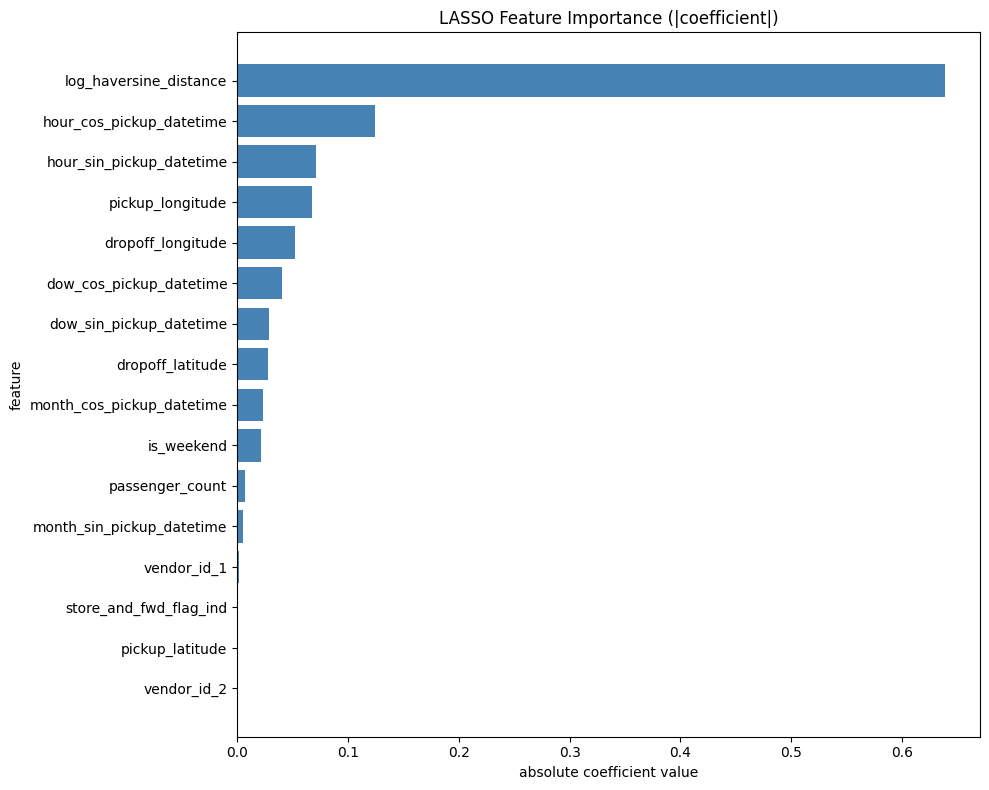

In [203]:
#LASSO feature importance

df_coef = pd.DataFrame({
    "feature": features,
    "coefficient": model.coef_
})

df_coef["abs_coefficient"] = df_coef["coefficient"].abs()
df_coef = df_coef.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

print(df_coef)

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(df_coef["feature"], df_coef["abs_coefficient"], color="steelblue")

ax.invert_yaxis()
ax.set_title("LASSO Feature Importance (|coefficient|)")
ax.set_xlabel("absolute coefficient value")
ax.set_ylabel("feature")

plt.tight_layout()
plt.show()


In [204]:
#Ridge

from sklearn.linear_model import RidgeCV

model_name = "ridge"

alphas = np.logspace(-3, 3, 50)

with mlflow.start_run(run_name="Ridge Regression"):
    model = RidgeCV(alphas=alphas, cv=5)
    model.fit(X_train_scaled, y_train)

    print(f"Best alpha: {model.alpha_:.6f}")

    y_val_pred = model.predict(X_val_scaled)

    rmse = root_mean_squared_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    rmsle = root_mean_squared_log_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    r2 = r2_score(y_val, y_val_pred)

    print(f"RMSE: {rmse:.4f}")
    print(f"RMSLE: {rmsle:.4f}")
    print(f"R2: {r2:.4f}")

    mlflow.log_param("alpha", model.alpha_)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("rmsle", rmsle)
    mlflow.log_metric("r2", r2)

    mlflow.sklearn.log_model(model, "model")

#predict on test set
y_test_pred_log = model.predict(X_test_scaled)

df_test_eval = df_test[["id"]].copy()
y_test_pred = np.expm1(y_test_pred_log)
df_test_eval["log_trip_duration"] = y_test_pred
df_test_eval.columns = ['id', 'trip_duration']
df_test_eval.to_csv(f'{project_root}/outputs/df_test_eval_{model_name}.csv', index = False)
print(f'exported {model_name} prediction')


2026/11/05 11:38:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Best alpha: 8.286428
RMSE: 418.4839
RMSLE: 0.4437
R2: 0.6549
exported ridge prediction


In [205]:
#random forest regressor

from sklearn.ensemble import RandomForestRegressor

model_name = "random_forest"

rf_params = {
    "n_estimators": 200,
    "max_depth": 30,
    "min_samples_split": 5,
    "min_samples_leaf": 10,
    "max_features": 0.5,
    "max_samples": 0.7,
    "n_jobs": -1,
    "random_state": 42
}

# check_previous_run(rf_params)

with mlflow.start_run(run_name="Random Forest"):
    model = RandomForestRegressor(**rf_params)
    model.fit(X_train_scaled, y_train)

    y_val_pred = model.predict(X_val_scaled)

    rmse = root_mean_squared_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    rmsle = root_mean_squared_log_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    r2 = r2_score(y_val, y_val_pred)

    print(f"RMSE: {rmse:.4f}")
    print(f"RMSLE: {rmsle:.4f}")
    print(f"R2: {r2:.4f}")

    mlflow.log_params(rf_params)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("rmsle", rmsle)
    mlflow.log_metric("r2", r2)

    #random forests store a sklearn.tree._tree.Tree internally, which skops
    #(mlflow's default serializer) flags as untrusted unless told otherwise
    mlflow.sklearn.log_model(
        model,
        "model",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

#predict on test set
y_test_pred_log = model.predict(X_test_scaled)

df_test_eval = df_test[["id"]].copy()
y_test_pred = np.expm1(y_test_pred_log)
df_test_eval["log_trip_duration"] = y_test_pred
df_test_eval.columns = ['id', 'trip_duration']
df_test_eval.to_csv(f'{project_root}/outputs/df_test_eval_{model_name}.csv', index = False)
print(f'exported {model_name} prediction')

2026/11/05 11:40:10 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


RMSE: 300.6364
RMSLE: 0.3503
R2: 0.7850
exported random_forest prediction


In [212]:
#xgboost

import xgboost as xgb

model_name = "xgboost"

xgb_params = {
    "n_estimators": 2000,
    "learning_rate": 0.03,

    "max_depth": 10, #default 6
    "min_child_weight": 3, #default 1

    "subsample": 0.8, #default 1
    "colsample_bytree": 0.8, #default 1

    "gamma": 0.1, #default 0
    "reg_alpha": 0, #default 0
    "reg_lambda": 1, #default 1

    "n_jobs": -1,

    "random_state": 42,
    "objective": 'reg:squarederror',
    "eval_metric":'rmse'
}

# check_previous_run(xgb_params)

with mlflow.start_run(run_name="XGBoost"):
    model = xgb.XGBRegressor(**xgb_params)
    model.fit(X_train_scaled, y_train)

    y_val_pred = model.predict(X_val_scaled)

    # rmse = root_mean_squared_error(y_val, y_val_pred)
    rmse = root_mean_squared_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    rmsle = root_mean_squared_log_error(
        np.expm1(y_val),
        np.clip(np.expm1(y_val_pred), a_min=0, a_max=None)
    )
    r2 = r2_score(y_val, y_val_pred)

    print(f"RMSE: {rmse:.4f}")
    print(f"RMSLE: {rmsle:.4f}")
    print(f"R2: {r2:.4f}")

    mlflow.log_params(xgb_params)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("rmsle", rmsle)
    mlflow.log_metric("r2", r2)

    #XGBRegressor wraps an xgboost Booster, both of which skops
    #(mlflow's default serializer) flags as untrusted unless told otherwise
    mlflow.sklearn.log_model(
        model,
        "model",
        skops_trusted_types=["xgboost.sklearn.XGBRegressor", "xgboost.core.Booster"]
    )

#predict on test set
y_test_pred_log = model.predict(X_test_scaled)

df_test_eval = df_test[["id"]].copy()
y_test_pred = np.expm1(y_test_pred_log)
df_test_eval["log_trip_duration"] = y_test_pred
df_test_eval.columns = ['id', 'trip_duration']
df_test_eval.to_csv(f'{project_root}/outputs/df_test_eval_{model_name}.csv', index = False)
print(f'exported {model_name} prediction')



2026/11/05 11:49:35 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


RMSE: 284.5815
RMSLE: 0.3312
R2: 0.8078
exported xgboost prediction


                      feature  importance
0          haversine_distance    0.530043
1                  is_weekend    0.080915
2    hour_cos_pickup_datetime    0.051020
3    hour_sin_pickup_datetime    0.042068
4            pickup_longitude    0.040155
5            dropoff_latitude    0.040032
6           dropoff_longitude    0.037565
7     dow_sin_pickup_datetime    0.036084
8             pickup_latitude    0.033855
9     dow_cos_pickup_datetime    0.023187
10                vendor_id_1    0.018873
11  month_cos_pickup_datetime    0.017628
12                vendor_id_2    0.016528
13  month_sin_pickup_datetime    0.011551
14            passenger_count    0.011286
15     store_and_fwd_flag_ind    0.009210


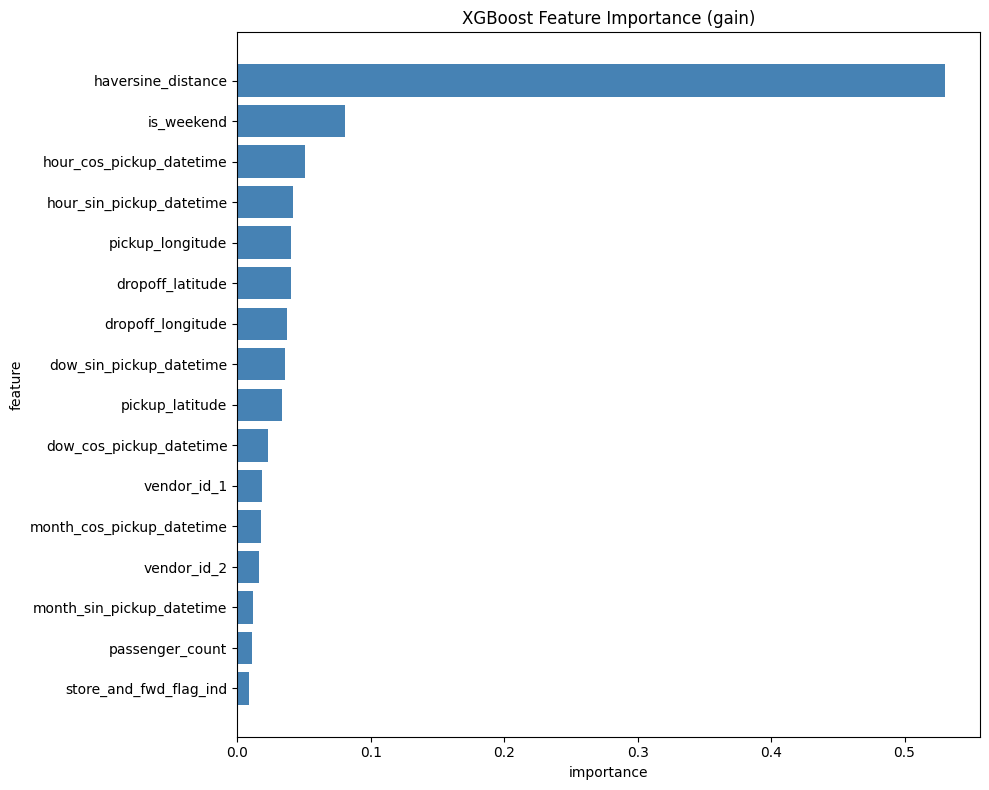

In [213]:
#xgboost feature selection

#feature_importances_ uses gain: the average improvement in the loss from splits on that feature
df_importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
})

df_importance = df_importance.sort_values("importance", ascending=False).reset_index(drop=True)

print(df_importance)

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(df_importance["feature"], df_importance["importance"], color="steelblue")

ax.invert_yaxis()
ax.set_title("XGBoost Feature Importance (gain)")
ax.set_xlabel("importance")
ax.set_ylabel("feature")

plt.tight_layout()
plt.show()

# 8. Conclusion

All models were trained on the same 16 features and the same 80/20 train/validation split, with log_trip_duration as the target. RMSLE (the competition metric) and RMSE are calculated on trip duration in seconds; R2 is on the log scale.

| Model | RMSLE | RMSE (seconds) | R2 | Kaggle RMSLE |
|---|---|---|---|---|
| Linear Regression | 0.4437 | 418.50 | 0.6549 | 0.50266 |
| LASSO | 0.4437 | 417.36 | 0.6549 | 0.50303 |
| Ridge | 0.4437 | 418.48 | 0.6549 | 0.50265 |
| Random Forest | 0.3503 | 300.64 | 0.7850 | 0.42637 |
| **XGBoost** | **0.3312** | **284.58** | **0.8078** | **0.39782** |

**Linear models**
- linear regression, LASSO and Ridge all scored the same RMSLE (0.4437), and the best alphas were small, so regularization made no difference
- this means the linear models weren't overfitting, they were underfitting: trip duration doesn't change linearly with the features (e.g. the effect of distance depends on time of day and location), and a linear model can't capture that

**Tree models**
- random forest lowered RMSLE by ~21% compared to the linear models (0.4437 → 0.3503) because trees can model nonlinear effects and interactions between distance, location and time
- XGBoost was the best model: RMSLE 0.3312, ~25% lower than the linear models and ~5% lower than random forest

**Feature importance (XGBoost)**
- haversine_distance is by far the most important feature, at 53% of total gain
- is_weekend (8%) and hour of day (hour_cos 5%, hour_sin 4%) come next, so when the trip happens matters after how far it goes
- pickup/dropoff coordinates each contribute 3–4%, likely capturing neighborhood and traffic effects
- passenger_count, store_and_fwd_flag_ind and month contribute the least (≤2% each)
- Further experimenting with data cleaning pertaining to minimum wait times for trips (10 seconds) and maximum trip durations (over 3 hours) aided in improving model efficacy. Testing as to which distance (haversine or manhattan) and log of non-log of them mildly influenced model efficacy as well.
